In [3]:
!pip install unidecode

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 235.8/235.8 kB 6.9 MB/s eta 0:00:00


In [4]:
import pandas as pd
import requests
from pathlib import Path
from unidecode import unidecode
import re

In [5]:
from google.colab import drive

drive.mount("/content/drive")
pasta = Path(
    "/content/drive/MyDrive/"
    "Colab Notebooks/"
    "Bloco 5/"
    "Projeto de Bloco: Inteligência Artificial Aplicada [26E3_5]"
    )


Mounted at /content/drive


---

In [8]:
df = pd.read_csv(f'{pasta}/noticias_19_09_2026.csv')
df

,titulo,data,texto,palavras,url,fonte
0,Inep divulga Cartilha de Redação do Enem 2026 ...,18/09/2026 - 11:08,"Reportagem do g1 mostrou que, em documento int...",905,https://g1.globo.com/educacao/enem/2026/notici...,g1 - Portal de notícias da Globo
1,23% dos jovens com dificuldade de mobilidade e...,18/09/2026 - 10:00,Levantamento do IBGE leva em conta brasileiros...,556,https://g1.globo.com/educacao/noticia/2026/09/...,g1 - Portal de notícias da Globo
2,Ensino superior faz renda subir até 110%; veja...,17/09/2026 - 15:00,"Levantamento aponta que 42,8% dos egressos cit...",1750,https://g1.globo.com/educacao/noticia/2026/09/...,g1 - Portal de notícias da Globo
3,Quanto ganha um professor no Brasil? Veja list...,17/09/2026 - 04:00,Pesquisa sobre risco de falta de professores m...,860,https://g1.globo.com/educacao/noticia/2026/09/...,g1 - Portal de notícias da Globo
4,"No Brasil, 67% dos alunos mais pobres não atin...",17/09/2026 - 00:00,"Análise do Instituto de Evidência Educativa, a...",599,https://g1.globo.com/educacao/noticia/2026/09/...,g1 - Portal de notícias da Globo
5,‘Apagão’: número de professores idosos mais do...,16/09/2026 - 15:00,Proximidade da aposentadoria para quantidade s...,753,https://g1.globo.com/educacao/noticia/2026/09/...,g1 - Portal de notícias da Globo
6,Dormir bem pode ajudar no desempenho escolar d...,16/09/2026 - 04:00,Pesquisadores analisaram como fatores como qua...,605,https://g1.globo.com/educacao/noticia/2026/09/...,g1 - Portal de notícias da Globo
7,O poder do recomeço: EJA transforma trajetória...,15/09/2026 - 12:58,Educação de Jovens e Adultos amplia oportunida...,944,https://g1.globo.com/educacao/especial-publici...,g1 - Portal de notícias da Globo
8,Cartilha reúne orientações para a redação do E...,18/09/2026 - 18:09,Os inscritos no Exame Nacional do Ensino Médio...,657,https://agenciabrasil.ebc.com.br/educacao/noti...,Agência Brasil - EBC
9,Analfabetismo entre jovens e adultos com defic...,18/09/2026 - 12:03,A taxa de analfabetismo entre as pessoas com d...,559,https://agenciabrasil.ebc.com.br/educacao/noti...,Agência Brasil - EBC


In [9]:
df.dtypes

,0
titulo,object
data,object
texto,object
palavras,int64
url,object
fonte,object


In [10]:
df['full_text'] = df['titulo'] + '\n' + df['texto']

In [11]:
## em tudo
# for col in df.columns:
#   if df[col].dtype == 'object':
#     # df[col] = df[col].astype('string')
#     df[col] = df[col].str.lower().str.strip().apply(unidecode)

df['full_text'] = df['full_text'].str.lower().str.strip().apply(unidecode)

In [12]:
df['full_text']

,full_text
0,inep divulga cartilha de redacao do enem 2026 ...
1,23% dos jovens com dificuldade de mobilidade e...
2,ensino superior faz renda subir ate 110%; veja...
3,quanto ganha um professor no brasil? veja list...
4,"no brasil, 67% dos alunos mais pobres nao atin..."
5,'apagao': numero de professores idosos mais do...
6,dormir bem pode ajudar no desempenho escolar d...
7,o poder do recomeco: eja transforma trajetoria...
8,cartilha reune orientacoes para a redacao do e...
9,analfabetismo entre jovens e adultos com defic...


In [13]:
df['full_text'].str.split()

,full_text
0,"[inep, divulga, cartilha, de, redacao, do, ene..."
1,"[23%, dos, jovens, com, dificuldade, de, mobil..."
2,"[ensino, superior, faz, renda, subir, ate, 110..."
3,"[quanto, ganha, um, professor, no, brasil?, ve..."
4,"[no, brasil,, 67%, dos, alunos, mais, pobres, ..."
5,"['apagao':, numero, de, professores, idosos, m..."
6,"[dormir, bem, pode, ajudar, no, desempenho, es..."
7,"[o, poder, do, recomeco:, eja, transforma, tra..."
8,"[cartilha, reune, orientacoes, para, a, redaca..."
9,"[analfabetismo, entre, jovens, e, adultos, com..."


In [14]:
df['full_text'] = df['full_text'].str.replace(r"[^\w\s]", "", regex=True)
df['full_text']

,full_text
0,inep divulga cartilha de redacao do enem 2026 ...
1,23 dos jovens com dificuldade de mobilidade e ...
2,ensino superior faz renda subir ate 110 veja 2...
3,quanto ganha um professor no brasil veja lista...
4,no brasil 67 dos alunos mais pobres nao atinge...
5,apagao numero de professores idosos mais do qu...
6,dormir bem pode ajudar no desempenho escolar d...
7,o poder do recomeco eja transforma trajetorias...
8,cartilha reune orientacoes para a redacao do e...
9,analfabetismo entre jovens e adultos com defic...


In [15]:
total_palavras = df['full_text'].str.split().str.len().sum()
total_palavras

np.int64(13956)

In [16]:
from nltk.corpus import stopwords
import nltk

nltk.download('stopwords')
stop_words  = stopwords.words('portuguese')
stop_words [::10]

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


['a',
 'às',
 'deles',
 'em',
 'está',
 'estejam',
 'estiverem',
 'fora',
 'haja',
 'houvera',
 'houveríamos',
 'mais',
 'não',
 'num',
 'por',
 'sem',
 'seus',
 'temos',
 'teriam',
 'tiver',
 'tua']

In [17]:
stop_words = [unidecode(word) for word in stop_words]
stop_words.append('us')
stop_words [::10]

['a',
 'as',
 'deles',
 'em',
 'esta',
 'estejam',
 'estiverem',
 'fora',
 'haja',
 'houvera',
 'houveriamos',
 'mais',
 'nao',
 'num',
 'por',
 'sem',
 'seus',
 'temos',
 'teriam',
 'tiver',
 'tua']

In [18]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(
    token_pattern=r"(?u)\b[A-Za-z][A-Za-z]+\b", # pelo menos 2 letras
    stop_words=stop_words,
    strip_accents='unicode',
    ngram_range=(1,1)
  )
bag_of_words = vectorizer.fit_transform(df['full_text'])
print('Tokens: ', bag_of_words.shape[1])

contagens = bag_of_words.sum(axis=0)
contagens = contagens.tolist()[0]

tokens = vectorizer.get_feature_names_out()

Tokens:  2590


In [138]:
print(tokens[::120])

['abaixo' 'ambas' 'atencao' 'caindo' 'comentarios' 'contra' 'desafio'
 'docencia' 'enviarem' 'exigencias' 'forum' 'importantes' 'lanca' 'medida'
 'nota' 'pedagogica' 'precisa' 'publicado' 'remunerado' 'segundo' 'taxa'
 'va']


In [140]:
palavras_significativas = len(tokens)
palavras_significativas

2590

In [141]:
freqs = [(word, count) for word, count in zip(tokens, contagens)]
freqs = sorted(freqs, key=lambda x: x[1], reverse=True)
freqs[:25]

[('ensino', 72),
 ('mil', 68),
 ('educacao', 63),
 ('anos', 51),
 ('professores', 48),
 ('brasil', 47),
 ('professor', 45),
 ('estudantes', 42),
 ('nacional', 40),
 ('prova', 38),
 ('superior', 34),
 ('exame', 33),
 ('formacao', 32),
 ('inep', 31),
 ('instituto', 31),
 ('deficiencia', 30),
 ('medio', 30),
 ('cursos', 29),
 ('escolas', 27),
 ('alem', 26),
 ('maior', 26),
 ('media', 26),
 ('graduacao', 25),
 ('nivel', 25),
 ('escola', 23)]

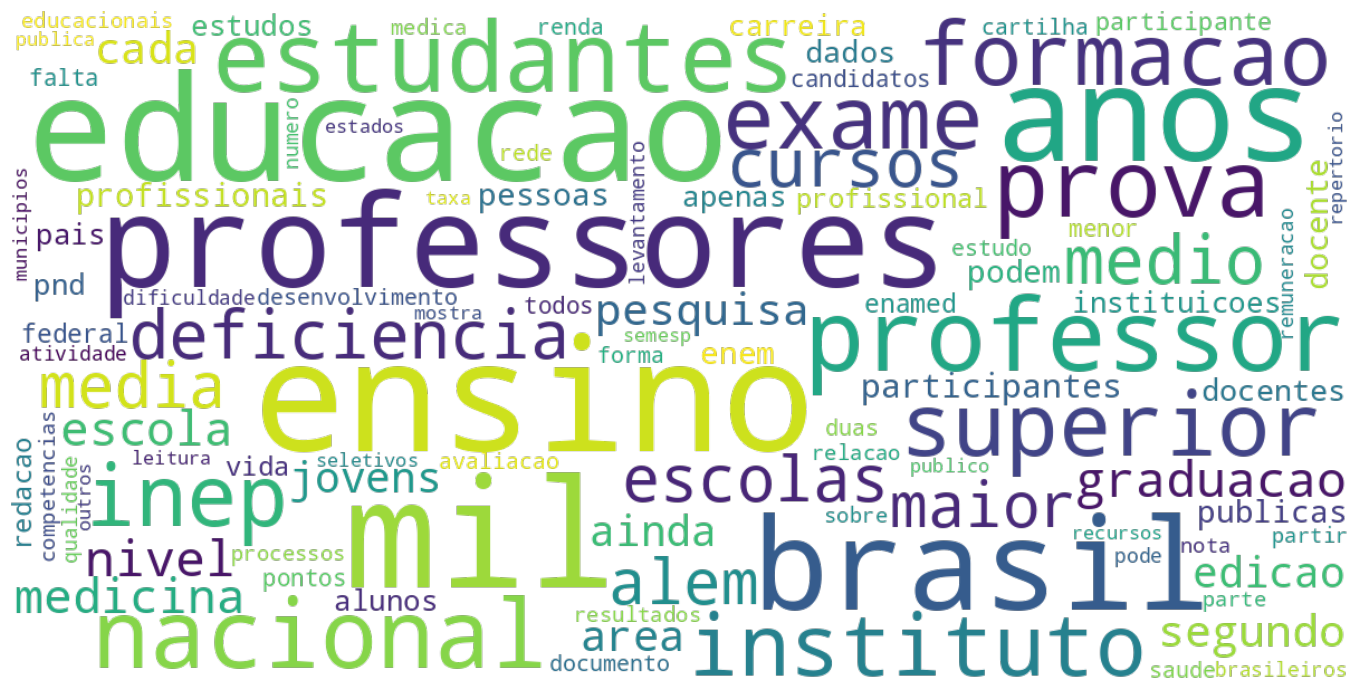

In [142]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud
# fazendo uma nuvem de palavras com as 100 de maior peso
wc = WordCloud(
    width=1200, height=600,
    background_color=None,
    mode='RGBA',
    max_words=100,
    min_font_size=8,
    max_font_size=140,
    prefer_horizontal=0.9
).generate_from_frequencies(dict(freqs))

plt.figure(figsize=(14, 7))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.tight_layout()
plt.show()